# IoT PULSE — Statistical Investigation of IoT Network Traffic and Attack Patterns
### A statistics-first Foundations of Data Science case study using RT-IOT2022

**Course:** 23CSE351 — Foundations of Data Science  
**Dataset supplied for this project:** `RT_IOT2022 (2)(1).csv`  
**Main focus:** Data preprocessing, descriptive statistics, exploratory analysis, hypothesis testing, effect sizes, and evidence-based conclusions.  
**Supporting technique:** One classification model to examine how well flow features distinguish the recorded `Attack_type` labels.

> **Important:** This notebook is designed around the supplied RT-IOT2022 dataset, not the previously suggested air-quality dataset. Place the CSV beside this notebook, or change `DATA_PATH` in Section 2. Run all cells from top to bottom. The code calculates the results from the actual CSV; it does not hard-code statistical findings.

**Research question:** How do recorded network-flow characteristics differ across attack labels, protocols, and services, and which observed differences have statistical support?

**Interpretation boundary:** This dataset contains labelled flow records and engineered network features. It does not, by itself, establish that a feature causes an attack, prove real-world detection performance on a different network, or show how common attacks are in the wider internet. Results describe this dataset and its collection conditions.

## 1. Problem statement and objectives

IoT networks use multiple protocols and services and can be exposed to different kinds of network activity. A dataset of flow-level features provides an opportunity to investigate whether traffic patterns vary across the supplied attack labels.

### Objectives
1. Audit the dataset's dimensions, data types, missingness, duplicates, and label distribution.
2. Preprocess the data transparently without treating a row-index-like field as a network measurement.
3. Use descriptive statistics and visualizations to examine protocols, services, packet counts, flow duration, flags, payload rates, and timing features.
4. Answer **15 analysis questions**, including formal null/alternative hypotheses and p-values where an inferential test is appropriate.
5. Include an observational two-group comparison with an effect size and confidence interval where feasible.
6. Fit one supporting classification model, evaluate it with class-aware metrics, and explain its limitations.
7. Export clean data and summary tables for Power BI/Tableau.

### Methodological principles
- Use α = 0.05 as a reference threshold, but do not treat a small p-value as proof of practical importance.
- Report sample sizes and effect sizes alongside p-values where practical.
- The dataset is highly class-imbalanced; accuracy alone is not an adequate model metric.
- Flow records may not be independent. Repeated or similar rows and shared collection conditions can make ordinary p-values optimistic.
- A train/test split from the same dataset measures within-dataset performance, not guaranteed performance on unseen networks.

## 2. Load the supplied dataset

The supplied file is expected to contain network-flow features and an `Attack_type` label. The source file contains 123,117 records and 85 columns in the supplied copy. This cell verifies the actual file rather than relying only on those expected dimensions.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, kruskal, mannwhitneyu, spearmanr
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

candidate_paths = [
    Path("RT_IOT2022 (2)(1).csv"),
    Path("RT_IOT2022 (2).csv"),
    Path("/mnt/data/RT_IOT2022 (2)(1).csv"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find RT_IOT2022 (2)(1).csv. Put the CSV beside this notebook "
        "or update DATA_PATH to the file's location."
    )

raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Loaded: /mnt/data/RT_IOT2022 (2)(1).csv
Shape: 123,117 rows × 85 columns


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.

## 3. Dataset audit and field roles

The dataset contains flow-level measurements such as protocol/service, duration, forward/backward packet counts, payload statistics, inter-arrival times, activity/idle statistics, TCP-window fields, and the target label `Attack_type`.

The `Unnamed: 0` field appears to be a row/index-like field, not a meaningful network measurement. It is excluded from statistical analysis and model predictors. Port fields are retained for descriptive analysis but excluded from the primary supporting model to reduce the risk that the model merely memorizes collection-specific port conventions.

In [2]:
print("Columns:")
print(raw.columns.tolist())
print("\nData types:")
display(raw.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("column_count"))

audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(3),
    "unique_values": raw.nunique(dropna=True)
}).sort_values(["missing_percent", "unique_values"], ascending=[False, True])
display(audit)

print(f"Exact duplicate rows in raw file: {raw.duplicated().sum():,}")
print(f"Records: {len(raw):,}; minimum requirement: 500")
assert len(raw) >= 500, "The case-study dataset must contain at least 500 records."
assert "Attack_type" in raw.columns, "Expected target column Attack_type was not found."

Columns:
['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max', 'f

,column_count
dtype,
float64,56
int64,26
object,3


,dtype,missing_count,missing_percent,unique_values
bwd_URG_flag_count,int64,0,0.0,1
fwd_URG_flag_count,int64,0,0.0,2
proto,object,0,0.0,3
flow_CWR_flag_count,int64,0,0.0,5
flow_ECE_flag_count,int64,0,0.0,5
fwd_header_size_min,int64,0,0.0,7
bwd_header_size_min,int64,0,0.0,7
fwd_header_size_max,int64,0,0.0,8
flow_SYN_flag_count,int64,0,0.0,8
bwd_header_size_max,int64,0,0.0,9


Exact duplicate rows in raw file: 0
Records: 123,117; minimum requirement: 500


## 4. Preprocessing and data-quality decisions

The preprocessing below is intentionally conservative:
1. Remove surrounding whitespace from column names and string categories.
2. Remove exact full-row duplicates, if any.
3. Exclude the index-like `Unnamed: 0` field from analysis.
4. Convert numeric feature columns to numeric types where possible.
5. Preserve genuine extreme flow measurements rather than deleting them automatically.
6. Do not replace missing measurements with zero. Missing values are reported, and model-specific imputation (if needed) is placed inside a pipeline.
7. Keep `Attack_type` as a categorical label.

**Duplicate caution:** Similar or identical feature values can occur for legitimate repeated flows. The notebook reports duplicates after excluding the row-index field but does not automatically delete those rows unless the entire original row is duplicated.

In [3]:
df = raw.copy()
df.columns = [str(c).strip() for c in df.columns]

for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

raw_duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Drop the index-like column from the analytical feature set.
index_like_cols = [c for c in df.columns if c.lower() in {"unnamed: 0", "index", "row_id"}]
df = df.drop(columns=index_like_cols, errors="ignore")

# Convert object columns to numeric only if nearly all non-null values parse as numbers.
for col in df.columns:
    if col == "Attack_type":
        continue
    if df[col].dtype == "object" or str(df[col].dtype) == "string":
        parsed = pd.to_numeric(df[col], errors="coerce")
        nonmissing = df[col].notna().sum()
        if nonmissing and parsed.notna().sum() / nonmissing >= 0.98:
            df[col] = parsed

if "Attack_type" not in df.columns:
    raise ValueError("Attack_type label missing after preprocessing.")

df["Attack_type"] = df["Attack_type"].astype("string").str.strip()
df = df.dropna(subset=["Attack_type"]).copy()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in df.columns if c not in numeric_cols]

print(f"Rows removed as exact full-row duplicates: {raw_duplicate_count:,}")
print(f"Analytical shape after basic cleaning: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Numeric features: {len(numeric_cols)}")
print(f"Categorical fields: {categorical_cols}")
print(f"Unique attack labels: {df['Attack_type'].nunique()}")
display(df.head())

Rows removed as exact full-row duplicates: 0
Analytical shape after basic cleaning: 123,117 rows × 84 columns
Numeric features: 81
Categorical fields: ['proto', 'service', 'Attack_type']
Unique attack labels: 12


,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286

### 4.1 Missing values and repeated feature signatures

,missing_count,missing_percent
id.orig_p,0,0.0
id.resp_p,0,0.0
proto,0,0.0
service,0,0.0
flow_duration,0,0.0
fwd_pkts_tot,0,0.0
bwd_pkts_tot,0,0.0
fwd_data_pkts_tot,0,0.0
bwd_data_pkts_tot,0,0.0
fwd_pkts_per_sec,0,0.0


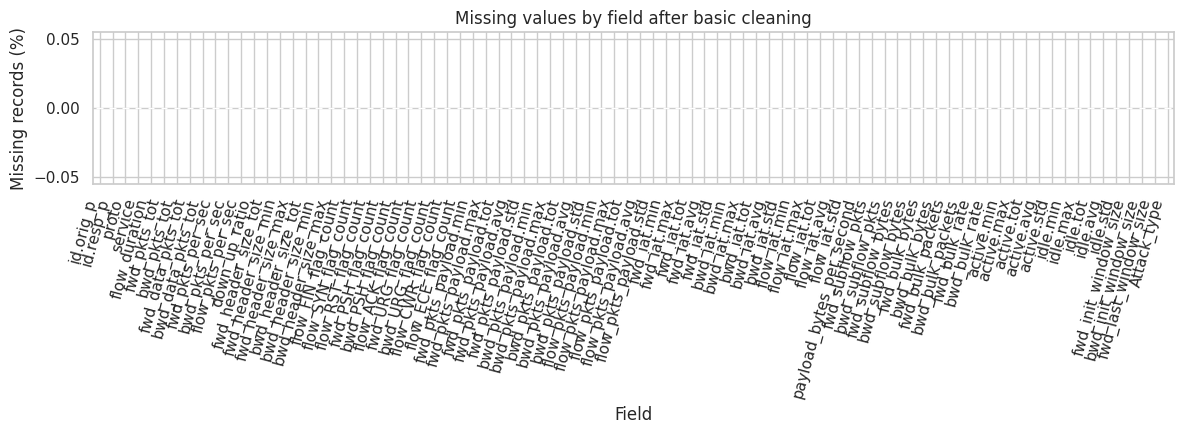

Rows with repeated feature signatures (label ignored): 5,202
These are reported, not automatically deleted: repeated flow patterns may be real, but they can affect independence assumptions.


In [4]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3)
}).sort_values("missing_percent", ascending=False)
display(missing_summary)

plt.figure(figsize=(12, 4.5))
missing_summary["missing_percent"].plot(kind="bar")
plt.title("Missing values by field after basic cleaning")
plt.xlabel("Field")
plt.ylabel("Missing records (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

feature_signature_duplicates = df.drop(columns=["Attack_type"], errors="ignore").duplicated().sum()
print(f"Rows with repeated feature signatures (label ignored): {feature_signature_duplicates:,}")
print("These are reported, not automatically deleted: repeated flow patterns may be real, but they can affect independence assumptions.")

### 4.2 Descriptive statistics and outlier review

Network-flow variables commonly have strongly skewed distributions and extreme values. We report mean, standard deviation, median, quartiles, and IQR. The 1.5×IQR rule flags observations for review but does not automatically remove them.

In [5]:
display(df[numeric_cols].describe(percentiles=[.25, .5, .75]).T)

outlier_rows = []
for col in numeric_cols:
    x = df[col].dropna()
    if len(x) == 0:
        continue
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "feature": col, "median": x.median(), "IQR": iqr,
        "lower_fence": low, "upper_fence": high,
        "flagged_count": int(((x < low) | (x > high)).sum()),
        "flagged_percent": float(((x < low) | (x > high)).mean() * 100)
    })
outlier_summary = pd.DataFrame(outlier_rows).sort_values("flagged_percent", ascending=False)
display(outlier_summary.head(20).round(3))

,count,mean,std,min,25%,50%,75%,max
id.orig_p,123117.0,3.463926e+04,1.907062e+04,0.0,17702.000000,3.722100e+04,5.097100e+04,6.553500e+04
id.resp_p,123117.0,1.014305e+03,5.256372e+03,0.0,21.000000,2.100000e+01,2.100000e+01,6.538900e+04
flow_duration,123117.0,3.809566e+00,1.300054e+02,0.0,0.000001,4.000000e-06,5.000000e-06,2.172834e+04
fwd_pkts_tot,123117.0,2.268826e+00,2.233656e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03
bwd_pkts_tot,123117.0,1.909509e+00,3.301831e+01,0.0,1.000000,1.000000e+00,1.000000e+00,1.011200e+04
fwd_data_pkts_tot,123117.0,1.471218e+00,1.963520e+01,0.0,1.000000,1.000000e+00,1.000000e+00,4.345000e+03
bwd_data_pkts_tot,123117.0,8.202604e-01,3.229395e+01,0.0,0.000000,0.000000e+00,0.000000e+00,1.010500e+04
fwd_pkts_per_sec,123117.0,3.518063e+05,3.707645e+05,0.0,74.543538,2.467238e+05,5.242880e+05,1.048576e+06
bwd_pkts_per_sec,123117.0,3.517620e+05,3.708015e+05,0.0,72.889275,2.467238e+05,5.242880e+05,1.048576e+06
flow_pkts_per_sec,123117.0,7.035683e+05,7.415634e+05,0.0,149.087077,4.934475e+05,1.048576e+06,2.097152e+06


,feature,median,IQR,lower_fence,upper_fence,flagged_count,flagged_percent
40,flow_pkts_payload.avg,60.0,0.0,60.0,60.0,38116,30.959
14,bwd_header_size_tot,20.0,0.0,20.0,20.0,33148,26.924
16,bwd_header_size_max,20.0,0.0,20.0,20.0,33137,26.915
22,flow_ACK_flag_count,1.0,0.0,1.0,1.0,33083,26.871
4,bwd_pkts_tot,1.0,0.0,1.0,1.0,32364,26.287
59,bwd_subflow_pkts,1.0,0.0,1.0,1.0,32343,26.270
15,bwd_header_size_min,20.0,0.0,20.0,20.0,32065,26.044
27,fwd_pkts_payload.min,120.0,0.0,120.0,120.0,28458,23.115
28,fwd_pkts_payload.max,120.0,0.0,120.0,120.0,28458,23.115
30,fwd_pkts_payload.avg,120.0,0.0,120.0,120.0,28458,23.115


## 5. Initial exploratory data analysis

### Target distribution: how imbalanced are the attack labels?

,records,percent
Attack_type,,
DOS_SYN_Hping,94659,76.885
Thing_Speak,8108,6.586
ARP_poisioning,7750,6.295
MQTT_Publish,4146,3.368
NMAP_UDP_SCAN,2590,2.104
NMAP_XMAS_TREE_SCAN,2010,1.633
NMAP_OS_DETECTION,2000,1.624
NMAP_TCP_scan,1002,0.814
DDOS_Slowloris,534,0.434


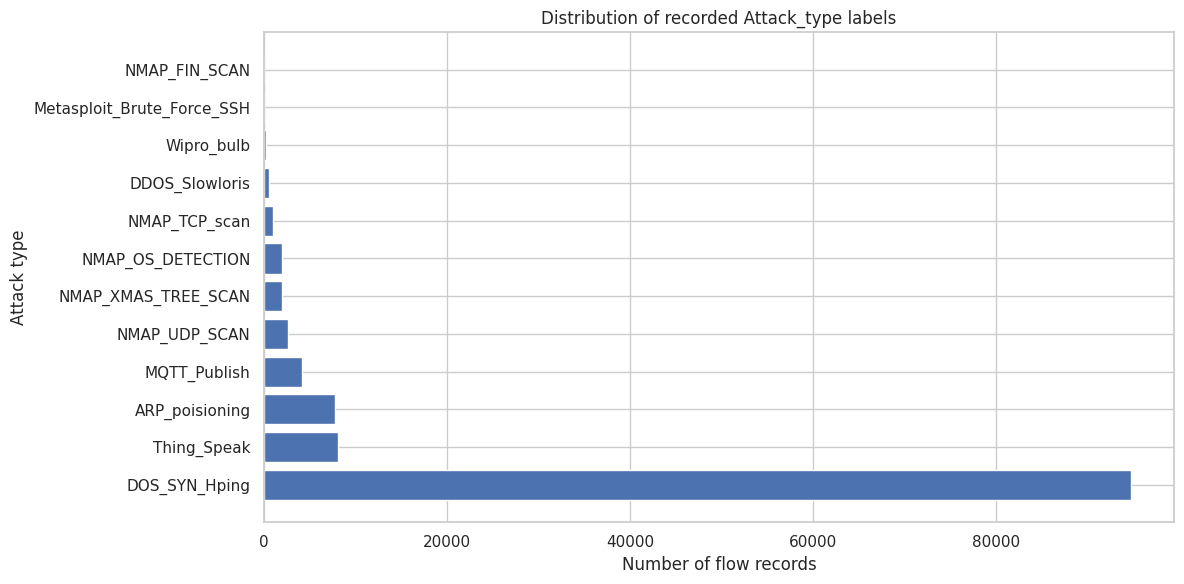

Majority-class share: 76.9%
Implication: accuracy alone can be misleading; use macro-F1, balanced accuracy, and per-class recall for the supporting model.


In [6]:
label_counts = df["Attack_type"].value_counts()
label_share = (label_counts / label_counts.sum() * 100).rename("percent")
label_summary = pd.concat([label_counts.rename("records"), label_share], axis=1)
display(label_summary.round(3))

plt.figure(figsize=(12, 6))
plt.barh(label_counts.index, label_counts.values)
plt.title("Distribution of recorded Attack_type labels")
plt.xlabel("Number of flow records")
plt.ylabel("Attack type")
plt.tight_layout()
plt.show()

print(f"Majority-class share: {label_counts.iloc[0] / label_counts.sum():.1%}")
print("Implication: accuracy alone can be misleading; use macro-F1, balanced accuracy, and per-class recall for the supporting model.")

### Protocol and service composition

Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb,All
proto,,,,,,,,,,,,,
icmp,8,0,0,0,0,0,0,0,2,0,45,2,57
tcp,1927,529,94659,4146,29,25,2000,1002,142,2007,3779,182,110427
udp,5815,5,0,0,8,3,0,0,2446,3,4284,69,12633
All,7750,534,94659,4146,37,28,2000,1002,2590,2010,8108,253,123117


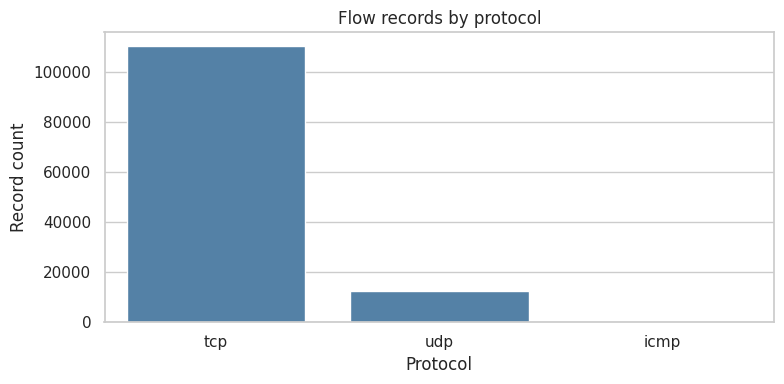

,records
service,
-,102861
dns,9753
mqtt,4132
http,3464
ssl,2663
ntp,121
dhcp,50
irc,43
ssh,28


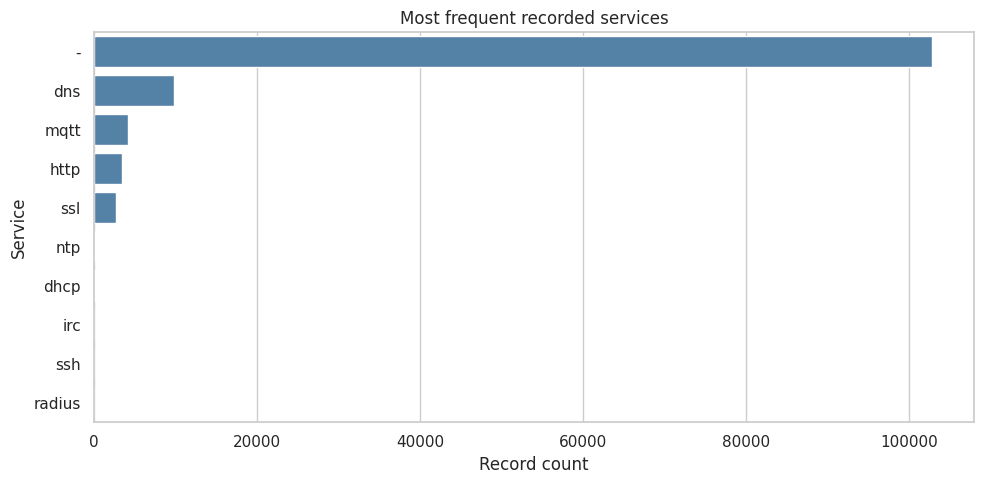

In [7]:
if "proto" in df.columns:
    display(pd.crosstab(df["proto"], df["Attack_type"], margins=True))
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x="proto", order=df["proto"].value_counts().index, color="steelblue")
    plt.title("Flow records by protocol")
    plt.xlabel("Protocol")
    plt.ylabel("Record count")
    plt.tight_layout()
    plt.show()

if "service" in df.columns:
    display(df["service"].value_counts().rename_axis("service").to_frame("records").head(15))
    plt.figure(figsize=(10, 5))
    top_services = df["service"].value_counts().head(12).index
    sns.countplot(data=df[df["service"].isin(top_services)], y="service", order=top_services, color="steelblue")
    plt.title("Most frequent recorded services")
    plt.xlabel("Record count")
    plt.ylabel("Service")
    plt.tight_layout()
    plt.show()

## 6. Statistical analysis: 15 questions

Each question below has a rationale and an analysis. Statistical tests are applied only when the data supports them. For large datasets, even small effects can produce tiny p-values, so practical effect size and data limitations must be discussed alongside statistical significance.

### Q1. Which `Attack_type` labels are most and least represented?

**Method:** Frequency table and class proportions.  
**Purpose:** Establish class balance before inferential testing or modelling.  
**Hypothesis test:** Not required for this descriptive question.  
**Interpretation:** Describe the dominant label and rare labels. These proportions describe the supplied dataset's collection mix, not real-world attack prevalence.

,records,percent
Attack_type,,
DOS_SYN_Hping,94659,76.885
Thing_Speak,8108,6.586
ARP_poisioning,7750,6.295
MQTT_Publish,4146,3.368
NMAP_UDP_SCAN,2590,2.104
NMAP_XMAS_TREE_SCAN,2010,1.633
NMAP_OS_DETECTION,2000,1.624
NMAP_TCP_scan,1002,0.814
DDOS_Slowloris,534,0.434


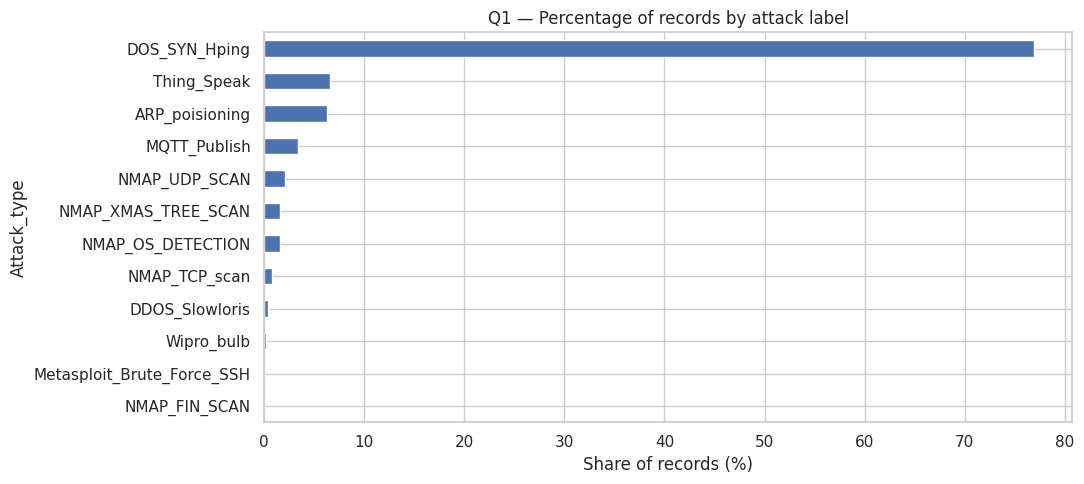

In [8]:
q1 = df["Attack_type"].value_counts().rename_axis("Attack_type").to_frame("records")
q1["percent"] = q1["records"] / q1["records"].sum() * 100
display(q1.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
q1.sort_values("percent")["percent"].plot(kind="barh", ax=ax)
ax.set_title("Q1 — Percentage of records by attack label")
ax.set_xlabel("Share of records (%)")
ax.set_ylabel("Attack_type")
plt.tight_layout()
plt.show()

### Q2. Does protocol distribution depend on the recorded attack label?

**Method:** Chi-square test of independence and Cramér's V.  
**\(H_0\):** `proto` and `Attack_type` are independent.  
**\(H_1\):** `proto` and `Attack_type` are associated.  
**Why:** Both fields are categorical.  
**Assumption check:** Report expected cells below 5. If many expected counts are small, interpret the asymptotic p-value cautiously.

Q2 chi-square=83803.125; df=22; p-value=0; Cramer's V=0.5834
Expected cells below 5: 13 / 36
Decision at alpha=0.05: Reject H0


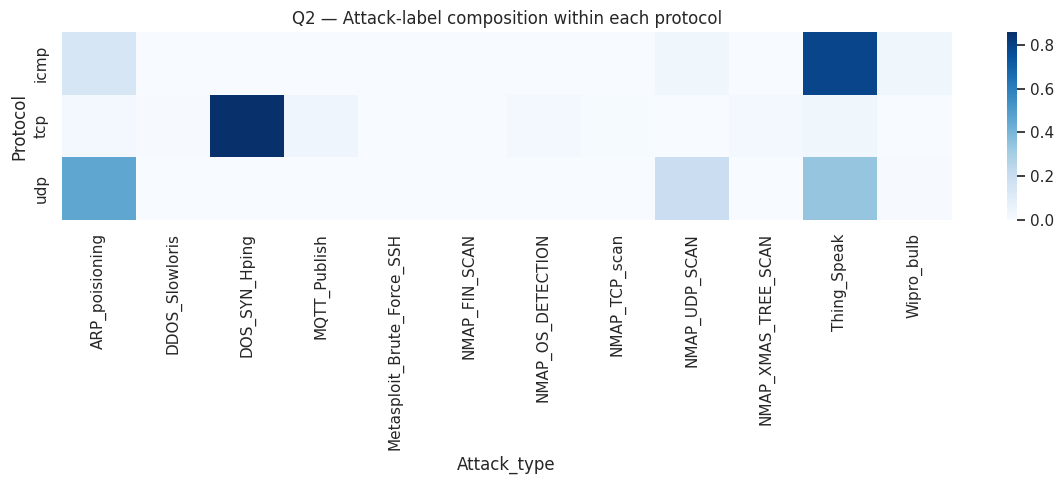

In [9]:
if "proto" in df.columns:
    ct = pd.crosstab(df["proto"], df["Attack_type"])
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1))) if min(r - 1, k - 1) > 0 else np.nan
    print(f"Q2 chi-square={chi2:.3f}; df={dof}; p-value={p:.6g}; Cramer's V={cramers_v:.4f}")
    print(f"Expected cells below 5: {(expected < 5).sum()} / {expected.size}")
    print("Decision at alpha=0.05:", "Reject H0" if p < .05 else "Fail to reject H0")
    row_prop = ct.div(ct.sum(axis=1), axis=0)
    plt.figure(figsize=(12, 5))
    sns.heatmap(row_prop, cmap="Blues", annot=False)
    plt.title("Q2 — Attack-label composition within each protocol")
    plt.xlabel("Attack_type")
    plt.ylabel("Protocol")
    plt.tight_layout()
    plt.show()

### Q3. Does service distribution depend on the attack label?

**Method:** Chi-square test of independence. To limit sparsity, services with fewer than 100 records are grouped into `Other service`; this grouping rule is defined before the test.  
**\(H_0\):** Service group and `Attack_type` are independent.  
**\(H_1\):** Service group and `Attack_type` are associated.  
**Interpretation:** Association can reflect how the dataset was generated and which services were used during data collection; it is not evidence that a service causes an attack.

Q3 chi-square=301729.097; df=66; p-value=0; Cramer's V=0.6391
Expected cells below 5: 26 / 84


Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
service,,,,,,,,,,,,
-,546,6,94659,11,0,24,2000,1002,2411,2006,151,45
Other service,26,2,0,0,28,0,0,0,5,0,14,48
dns,5583,3,0,0,8,3,0,0,31,3,4069,53
http,129,523,0,3,1,1,0,0,139,1,2667,0
mqtt,0,0,0,4132,0,0,0,0,0,0,0,0
ntp,7,0,0,0,0,0,0,0,4,0,110,0
ssl,1459,0,0,0,0,0,0,0,0,0,1097,107


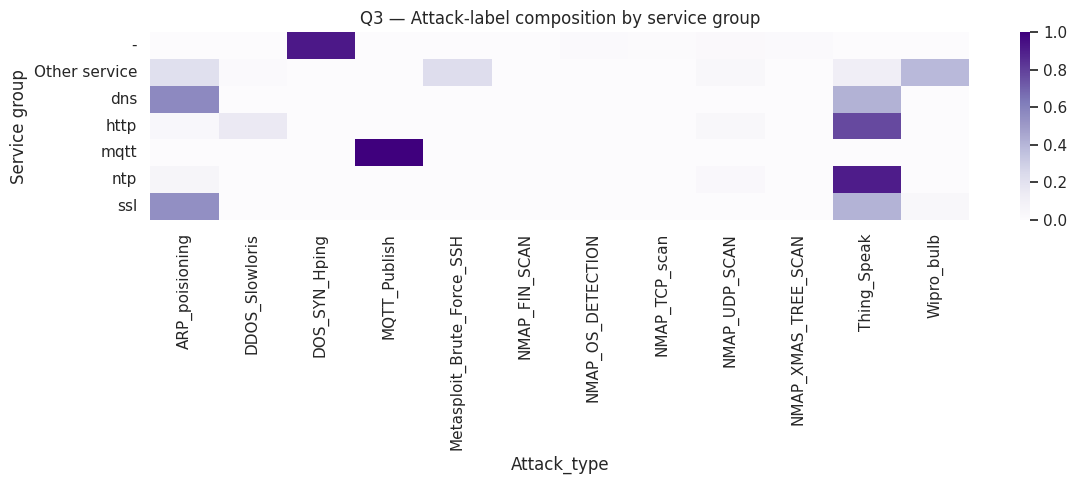

In [10]:
if "service" in df.columns:
    service_counts = df["service"].value_counts()
    common_services = service_counts[service_counts >= 100].index
    service_group = df["service"].where(df["service"].isin(common_services), "Other service")
    ct_service = pd.crosstab(service_group, df["Attack_type"])
    chi2, p, dof, expected = chi2_contingency(ct_service)
    n = ct_service.to_numpy().sum()
    r, k = ct_service.shape
    cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1))) if min(r - 1, k - 1) > 0 else np.nan
    print(f"Q3 chi-square={chi2:.3f}; df={dof}; p-value={p:.6g}; Cramer's V={cramers_v:.4f}")
    print(f"Expected cells below 5: {(expected < 5).sum()} / {expected.size}")
    display(ct_service)
    prop = ct_service.div(ct_service.sum(axis=1), axis=0)
    plt.figure(figsize=(12, 5))
    sns.heatmap(prop, cmap="Purples")
    plt.title("Q3 — Attack-label composition by service group")
    plt.xlabel("Attack_type")
    plt.ylabel("Service group")
    plt.tight_layout()
    plt.show()

### Q4. Does flow duration differ across attack labels?

**Method:** Kruskal–Wallis test on `flow_duration`, with attack groups having at least 30 records.  
**\(H_0\):** The flow-duration distributions are the same across included attack labels.  
**\(H_1\):** At least one distribution differs.  
**Why:** Flow duration is often skewed and can contain extreme values.  
**Interpretation:** A significant omnibus result does not identify which pairs differ. Do not claim a causal effect.

,count,median,mean,std
Attack_type,,,,
MQTT_Publish,4146,44.0676,43.3970,24.3416
DDOS_Slowloris,534,20.0890,14.6991,14.1248
Metasploit_Brute_Force_SSH,37,2.0303,3.0066,5.2103
Wipro_bulb,253,0.8033,586.8457,2738.8916
Thing_Speak,8108,0.1148,0.9345,5.2516
ARP_poisioning,7750,0.0006,15.8935,108.2611
NMAP_XMAS_TREE_SCAN,2010,0.0000,0.0012,0.0504
NMAP_OS_DETECTION,2000,0.0000,0.0000,0.0000
NMAP_TCP_scan,1002,0.0000,0.0000,0.0003


Q4 Kruskal-Wallis H=44749.4775; p-value=0; groups=11
Decision: Reject H0


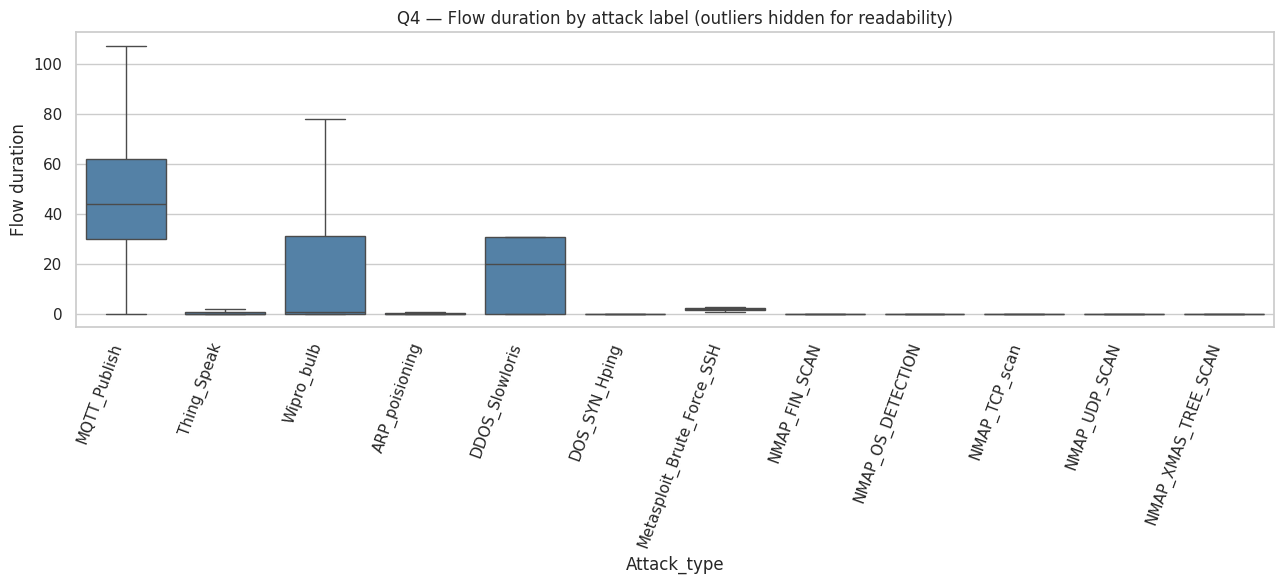

In [11]:
if "flow_duration" in df.columns:
    groups = []
    group_names = []
    for name, g in df.groupby("Attack_type"):
        x = g["flow_duration"].dropna()
        if len(x) >= 30:
            groups.append(x.to_numpy())
            group_names.append(name)
    summary = df.groupby("Attack_type")["flow_duration"].agg(["count", "median", "mean", "std"]).sort_values("median", ascending=False)
    display(summary.round(4))
    if len(groups) >= 2:
        H, p = kruskal(*groups)
        print(f"Q4 Kruskal-Wallis H={H:.4f}; p-value={p:.6g}; groups={len(groups)}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plt.figure(figsize=(13, 6))
    sns.boxplot(data=df, x="Attack_type", y="flow_duration", showfliers=False, color="steelblue")
    plt.title("Q4 — Flow duration by attack label (outliers hidden for readability)")
    plt.xlabel("Attack_type")
    plt.ylabel("Flow duration")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

### Q5. Does total packet count differ across attack labels?

Create `total_pkts = fwd_pkts_tot + bwd_pkts_tot`. Use a Kruskal–Wallis test across attack groups with at least 30 non-missing values.  
**\(H_0\):** Total-packet-count distributions are the same across included labels.  
**\(H_1\):** At least one differs.  
**Why:** Packet counts are non-negative and commonly skewed.  
**Interpretation:** Report medians and the omnibus p-value; use post-hoc testing with multiplicity correction only if you need to identify specific label pairs.

,count,median,mean,std
Attack_type,,,,
Metasploit_Brute_Force_SSH,37,27.0,22.865,12.917
Wipro_bulb,253,21.0,97.656,415.961
MQTT_Publish,4146,16.0,18.450,182.726
DDOS_Slowloris,534,9.0,11.077,4.794
Thing_Speak,8108,4.0,9.844,10.037
ARP_poisioning,7750,4.0,16.975,101.641
DOS_SYN_Hping,94659,2.0,1.898,0.303
NMAP_OS_DETECTION,2000,2.0,2.000,0.000
NMAP_XMAS_TREE_SCAN,2010,2.0,2.000,0.240


Q5 Kruskal-Wallis H=59302.9447; p-value=0; groups=11
Decision: Reject H0


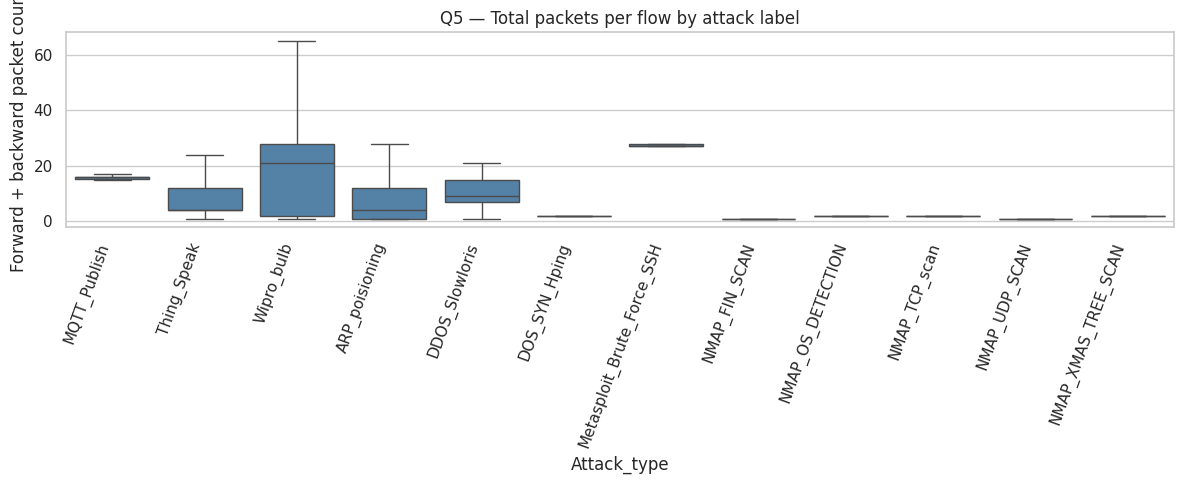

In [12]:
if {"fwd_pkts_tot", "bwd_pkts_tot"}.issubset(df.columns):
    df["total_pkts"] = df["fwd_pkts_tot"] + df["bwd_pkts_tot"]
    groups, names = [], []
    for name, g in df.groupby("Attack_type"):
        x = g["total_pkts"].dropna()
        if len(x) >= 30:
            groups.append(x.to_numpy())
            names.append(name)
    q5_summary = df.groupby("Attack_type")["total_pkts"].agg(["count", "median", "mean", "std"]).sort_values("median", ascending=False)
    display(q5_summary.round(3))
    if len(groups) >= 2:
        H, p = kruskal(*groups)
        print(f"Q5 Kruskal-Wallis H={H:.4f}; p-value={p:.6g}; groups={len(groups)}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df, x="Attack_type", y="total_pkts", showfliers=False, color="steelblue")
    plt.title("Q5 — Total packets per flow by attack label")
    plt.xlabel("Attack_type")
    plt.ylabel("Forward + backward packet count")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

### Q6. Are forward and backward packet counts associated?

**Method:** Spearman rank correlation.  
**\(H_0\):** Population rank correlation between `fwd_pkts_tot` and `bwd_pkts_tot` is zero.  
**\(H_1\):** It is non-zero.  
**Why:** Packet counts are skewed, may contain outliers, and the association may not be linear.  
**Interpretation:** Correlation describes co-movement, not a causal relationship.

Q6 n=123,117; Spearman rho=0.7463; p-value=0
Decision: Reject H0


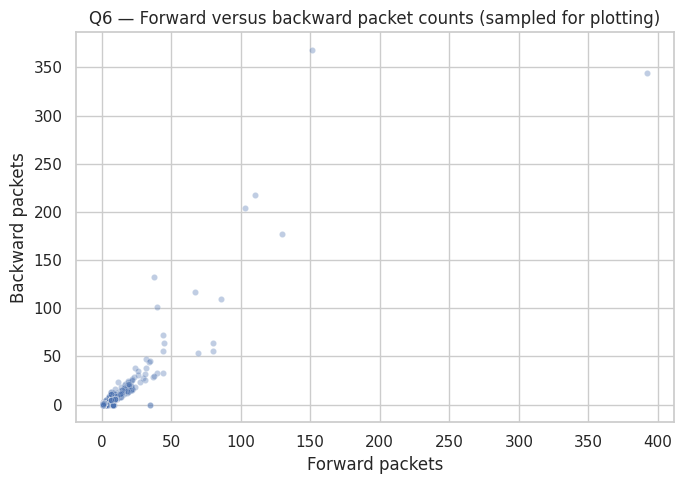

In [13]:
if {"fwd_pkts_tot", "bwd_pkts_tot"}.issubset(df.columns):
    pair = df[["fwd_pkts_tot", "bwd_pkts_tot"]].dropna()
    rho, p = spearmanr(pair["fwd_pkts_tot"], pair["bwd_pkts_tot"])
    print(f"Q6 n={len(pair):,}; Spearman rho={rho:.4f}; p-value={p:.6g}")
    print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    sample = pair.sample(min(8000, len(pair)), random_state=42)
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=sample, x="fwd_pkts_tot", y="bwd_pkts_tot", alpha=.35, s=20)
    plt.title("Q6 — Forward versus backward packet counts (sampled for plotting)")
    plt.xlabel("Forward packets")
    plt.ylabel("Backward packets")
    plt.tight_layout()
    plt.show()

### Q7. Does packet rate differ between TCP and UDP flows?

**Method:** Mann–Whitney U test on `flow_pkts_per_sec` for TCP versus UDP.  
**\(H_0\):** The two groups have the same distribution.  
**\(H_1\):** Their distributions differ.  
**Why:** The measure may be skewed, and the groups are independent in the observed table.  
**Effect size:** Rank-biserial correlation based on U, reported with the test result.  
**Caution:** The groups are not randomized and may differ in attack-label composition.

TCP n=110,427; median=493447.5294; UDP n=12,633; median=46.7311
Q7 Mann–Whitney U=1207681478.500; p-value=0; rank-biserial effect=0.7314
Decision: Reject H0


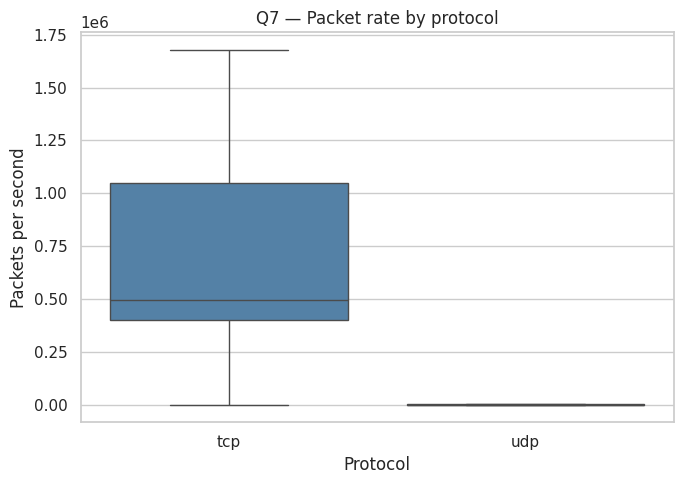

In [14]:
if {"proto", "flow_pkts_per_sec"}.issubset(df.columns):
    tcp = df.loc[df["proto"].str.lower() == "tcp", "flow_pkts_per_sec"].dropna()
    udp = df.loc[df["proto"].str.lower() == "udp", "flow_pkts_per_sec"].dropna()
    print(f"TCP n={len(tcp):,}; median={tcp.median():.4f}; UDP n={len(udp):,}; median={udp.median():.4f}")
    if len(tcp) and len(udp):
        U, p = mannwhitneyu(tcp, udp, alternative="two-sided")
        rbc = 2 * U / (len(tcp) * len(udp)) - 1
        print(f"Q7 Mann–Whitney U={U:.3f}; p-value={p:.6g}; rank-biserial effect={rbc:.4f}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plot_df = df[df["proto"].str.lower().isin(["tcp", "udp"])]
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=plot_df, x="proto", y="flow_pkts_per_sec", showfliers=False, color="steelblue")
    plt.title("Q7 — Packet rate by protocol")
    plt.xlabel("Protocol")
    plt.ylabel("Packets per second")
    plt.tight_layout()
    plt.show()

### Q8. Do payload-byte rates differ between TCP and UDP?

**Method:** Mann–Whitney U test on `payload_bytes_per_second`, plus medians and rank-biserial effect size.  
**\(H_0\):** TCP and UDP payload-rate distributions are equal.  
**\(H_1\):** They differ.  
**Interpretation:** A significant difference is an association in this sample. It can reflect application/service mix or collection design, not necessarily protocol behaviour alone.

Q8 TCP median=29606851.765; UDP median=2937.831
Mann–Whitney U=1159424197.500; p-value=0; rank-biserial effect=0.6622
Decision: Reject H0


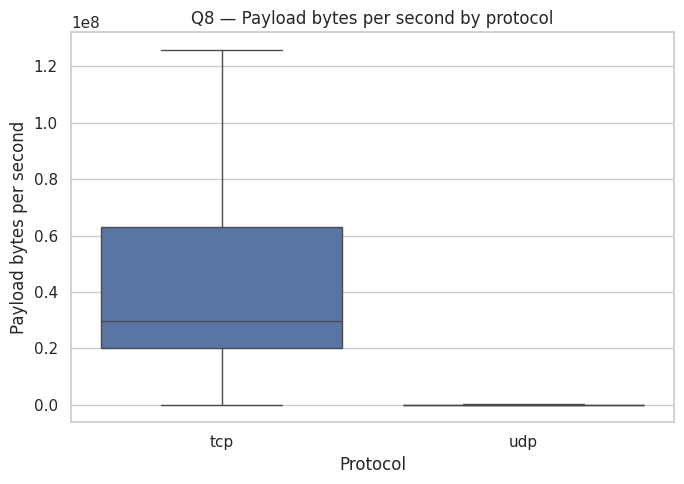

In [15]:
if {"proto", "payload_bytes_per_second"}.issubset(df.columns):
    tcp = df.loc[df["proto"].str.lower() == "tcp", "payload_bytes_per_second"].dropna()
    udp = df.loc[df["proto"].str.lower() == "udp", "payload_bytes_per_second"].dropna()
    if len(tcp) and len(udp):
        U, p = mannwhitneyu(tcp, udp, alternative="two-sided")
        rbc = 2 * U / (len(tcp) * len(udp)) - 1
        print(f"Q8 TCP median={tcp.median():.3f}; UDP median={udp.median():.3f}")
        print(f"Mann–Whitney U={U:.3f}; p-value={p:.6g}; rank-biserial effect={rbc:.4f}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df[df["proto"].str.lower().isin(["tcp", "udp"])],
                x="proto", y="payload_bytes_per_second", showfliers=False)
    plt.title("Q8 — Payload bytes per second by protocol")
    plt.xlabel("Protocol")
    plt.ylabel("Payload bytes per second")
    plt.tight_layout()
    plt.show()

### Q9. Is the SYN-flag count associated with the attack label?

**Method:** Kruskal–Wallis test of `flow_SYN_flag_count` across attack labels with at least 30 observations.  
**\(H_0\):** SYN-flag-count distributions are equal across included labels.  
**\(H_1\):** At least one label differs.  
**Why:** The feature is a count and may be skewed.  
**Interpretation:** This can identify label-associated differences in recorded SYN behaviour, but it does not prove that SYN counts alone identify an attack in a new network.

,count,median,mean,std
Attack_type,,,,
DDOS_Slowloris,534,2.0,2.015,0.267
MQTT_Publish,4146,2.0,1.997,0.097
Wipro_bulb,253,2.0,1.375,1.197
Metasploit_Brute_Force_SSH,37,2.0,1.568,0.835
NMAP_TCP_scan,1002,1.0,1.001,0.071
DOS_SYN_Hping,94659,1.0,1.000,0.000
ARP_poisioning,7750,0.0,0.489,0.875
NMAP_FIN_SCAN,28,0.0,0.071,0.378
NMAP_OS_DETECTION,2000,0.0,0.000,0.000


Q9 Kruskal-Wallis H=57883.1961; p-value=0
Decision: Reject H0


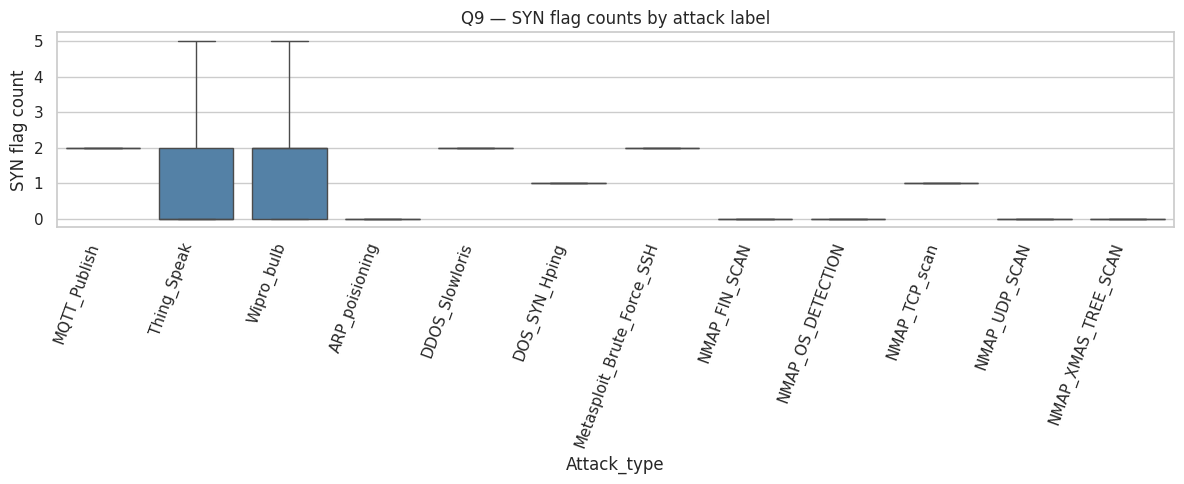

In [16]:
if "flow_SYN_flag_count" in df.columns:
    groups, names = [], []
    for name, g in df.groupby("Attack_type"):
        x = g["flow_SYN_flag_count"].dropna()
        if len(x) >= 30:
            groups.append(x.to_numpy())
            names.append(name)
    syn_summary = df.groupby("Attack_type")["flow_SYN_flag_count"].agg(["count", "median", "mean", "std"]).sort_values("median", ascending=False)
    display(syn_summary.round(3))
    if len(groups) >= 2:
        H, p = kruskal(*groups)
        print(f"Q9 Kruskal-Wallis H={H:.4f}; p-value={p:.6g}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df, x="Attack_type", y="flow_SYN_flag_count", showfliers=False, color="steelblue")
    plt.title("Q9 — SYN flag counts by attack label")
    plt.xlabel("Attack_type")
    plt.ylabel("SYN flag count")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

### Q10. Is a high-SYN flow more likely to belong to `DOS_SYN_Hping` than to other labels?

**Method:** Define high-SYN as `flow_SYN_flag_count` greater than the 75th percentile across all rows. Compare the proportion of high-SYN flows between `DOS_SYN_Hping` and all other labels using a two-proportion z-test. Report a confidence interval for the proportion difference.  
**\(H_0\):** The high-SYN proportions are equal.  
**\(H_1\):** They differ.  
**Caution:** This is an observational comparison and the threshold is data-defined. It is not a randomized experiment or a universal attack rule.

,high_SYN_records,n,proportion
group,,,
DOS_SYN_Hping,0,94659,0.0000
Other labels,10571,28458,0.3715


High-SYN threshold (75th percentile): 1.0
Q10 difference in proportions=-0.3715; approximate 95% CI=(-0.3771, -0.3658)
Two-proportion z=-196.1240; p-value=0
Decision: Reject H0


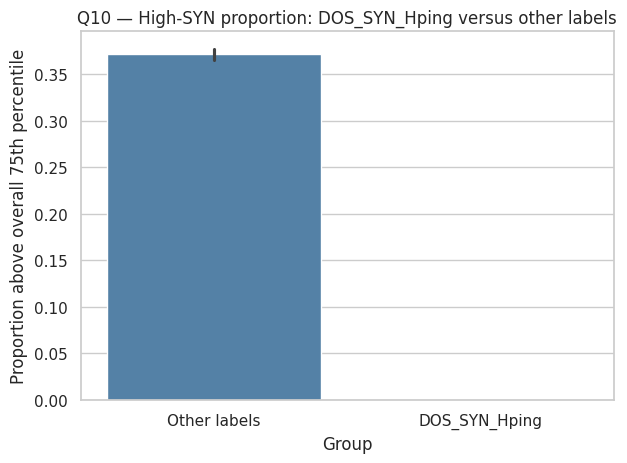

In [17]:
if "flow_SYN_flag_count" in df.columns:
    threshold = df["flow_SYN_flag_count"].quantile(.75)
    tmp = df[["Attack_type", "flow_SYN_flag_count"]].dropna().copy()
    tmp["high_syn"] = (tmp["flow_SYN_flag_count"] > threshold).astype(int)
    tmp["group"] = np.where(tmp["Attack_type"] == "DOS_SYN_Hping", "DOS_SYN_Hping", "Other labels")
    tab = tmp.groupby("group")["high_syn"].agg(["sum", "count", "mean"]).reindex(["DOS_SYN_Hping", "Other labels"])
    display(tab.rename(columns={"sum": "high_SYN_records", "count": "n", "mean": "proportion"}).round(4))
    print(f"High-SYN threshold (75th percentile): {threshold}")
    if tab["count"].notna().all() and (tab["count"] > 0).all():
        x1, n1 = int(tab.loc["DOS_SYN_Hping", "sum"]), int(tab.loc["DOS_SYN_Hping", "count"])
        x2, n2 = int(tab.loc["Other labels", "sum"]), int(tab.loc["Other labels", "count"])
        p1, p2 = x1/n1, x2/n2
        pooled = (x1+x2)/(n1+n2)
        se0 = np.sqrt(pooled*(1-pooled)*(1/n1+1/n2))
        z = (p1-p2)/se0 if se0 > 0 else np.nan
        pval = 2*stats.norm.sf(abs(z)) if np.isfinite(z) else np.nan
        se_diff = np.sqrt(p1*(1-p1)/n1 + p2*(1-p2)/n2)
        ci = (p1-p2-1.96*se_diff, p1-p2+1.96*se_diff)
        print(f"Q10 difference in proportions={p1-p2:.4f}; approximate 95% CI=({ci[0]:.4f}, {ci[1]:.4f})")
        print(f"Two-proportion z={z:.4f}; p-value={pval:.6g}")
        print("Decision:", "Reject H0" if pval < .05 else "Fail to reject H0")
    sns.barplot(data=tmp, x="group", y="high_syn", errorbar=("ci", 95), color="steelblue")
    plt.title("Q10 — High-SYN proportion: DOS_SYN_Hping versus other labels")
    plt.xlabel("Group")
    plt.ylabel("Proportion above overall 75th percentile")
    plt.tight_layout()
    plt.show()

### Q11. Is flow duration associated with packet rate?

**Method:** Spearman rank correlation between `flow_duration` and `flow_pkts_per_sec`.  
**\(H_0\):** The population rank correlation is zero.  
**\(H_1\):** It is non-zero.  
**Why:** Both measures can be skewed and the relationship may not be linear.  
**Interpretation:** A correlation is a descriptive association. Check the scatterplot and remember that rate calculations may mathematically depend on duration and packet counts.

Q11 n=123,117; Spearman rho=-0.2959; p-value=0
Decision: Reject H0


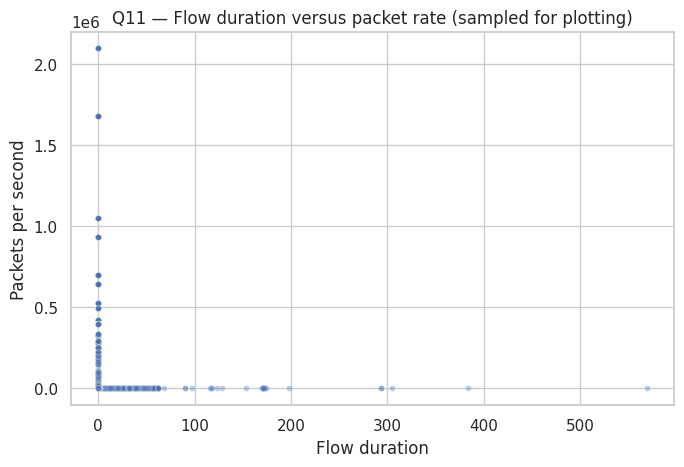

In [18]:
needed = {"flow_duration", "flow_pkts_per_sec"}
if needed.issubset(df.columns):
    pair = df[list(needed)].replace([np.inf, -np.inf], np.nan).dropna()
    rho, p = spearmanr(pair["flow_duration"], pair["flow_pkts_per_sec"])
    print(f"Q11 n={len(pair):,}; Spearman rho={rho:.4f}; p-value={p:.6g}")
    print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    sample = pair.sample(min(8000, len(pair)), random_state=42)
    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=sample, x="flow_duration", y="flow_pkts_per_sec", alpha=.35, s=18)
    plt.title("Q11 — Flow duration versus packet rate (sampled for plotting)")
    plt.xlabel("Flow duration")
    plt.ylabel("Packets per second")
    plt.tight_layout()
    plt.show()

### Q12. Which numeric flow features are most correlated with one another?

**Method:** Spearman correlation matrix for a small, preselected set of interpretable flow features.  
**Hypothesis:** This is exploratory correlation analysis; individual tests are not interpreted as confirmatory claims.  
**Purpose:** Identify redundancy and possible multicollinearity before modelling.  
**Interpretation:** Strong correlations can arise because features are derived from the same underlying counts, durations, or rates.

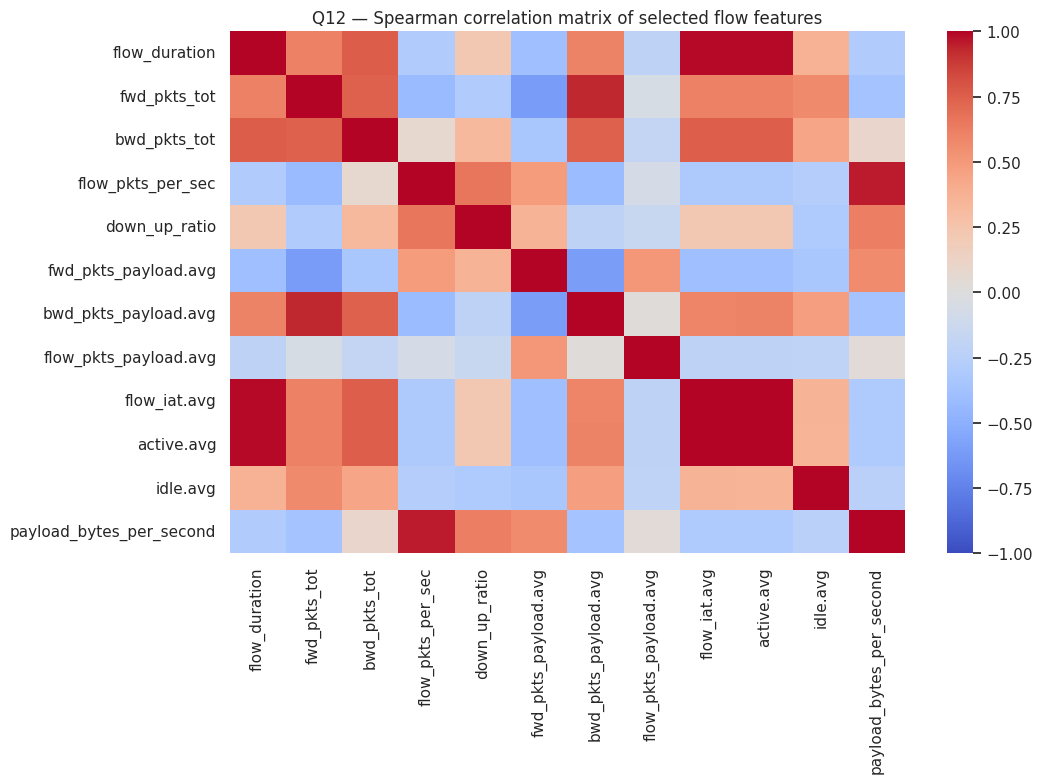

,flow_duration,fwd_pkts_tot,bwd_pkts_tot,flow_pkts_per_sec,down_up_ratio,fwd_pkts_payload.avg,bwd_pkts_payload.avg,flow_pkts_payload.avg,flow_iat.avg,active.avg,idle.avg,payload_bytes_per_second
flow_duration,1.000,0.616,0.760,-0.296,0.221,-0.394,0.607,-0.215,0.992,0.991,0.370,-0.289
fwd_pkts_tot,0.616,1.000,0.746,-0.424,-0.290,-0.610,0.937,-0.050,0.609,0.610,0.578,-0.367
bwd_pkts_tot,0.760,0.746,1.000,0.073,0.327,-0.341,0.750,-0.173,0.753,0.754,0.442,0.095
flow_pkts_per_sec,-0.296,-0.424,0.073,1.000,0.664,0.485,-0.419,-0.067,-0.310,-0.309,-0.267,0.961
down_up_ratio,0.221,-0.290,0.327,0.664,1.000,0.366,-0.219,-0.155,0.219,0.220,-0.302,0.619
fwd_pkts_payload.avg,-0.394,-0.610,-0.341,0.485,0.366,1.000,-0.606,0.511,-0.393,-0.392,-0.339,0.567
bwd_pkts_payload.avg,0.607,0.937,0.750,-0.419,-0.219,-0.606,1.000,0.023,0.601,0.602,0.476,-0.360
flow_pkts_payload.avg,-0.215,-0.050,-0.173,-0.067,-0.155,0.511,0.023,1.000,-0.215,-0.213,-0.207,0.038
flow_iat.avg,0.992,0.609,0.753,-0.310,0.219,-0.393,0.601,-0.215,1.000,0.999,0.367,-0.303
active.avg,0.991,0.610,0.754,-0.309,0.220,-0.392,0.602,-0.213,0.999,1.000,0.355,-0.302


In [19]:
selected_corr = [c for c in [
    "flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec",
    "down_up_ratio", "fwd_pkts_payload.avg", "bwd_pkts_payload.avg",
    "flow_pkts_payload.avg", "flow_iat.avg", "active.avg", "idle.avg",
    "payload_bytes_per_second"
] if c in df.columns]
if len(selected_corr) >= 2:
    corr_matrix = df[selected_corr].corr(method="spearman")
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title("Q12 — Spearman correlation matrix of selected flow features")
    plt.tight_layout()
    plt.show()
    display(corr_matrix.round(3))

### Q13. Does the forward/backward packet ratio differ by attack label?

**Method:** Compare `down_up_ratio` distributions using Kruskal–Wallis across labels with at least 30 observations.  
**\(H_0\):** The distributions are equal across included attack labels.  
**\(H_1\):** At least one differs.  
**Interpretation:** Directional imbalance may distinguish observed traffic groups, but a pooled test does not tell us which labels differ. Check how the ratio is defined in the dataset documentation before assigning a network meaning to it.

,count,median,mean,std
Attack_type,,,,
DOS_SYN_Hping,94659,1.0000,0.8976,0.3031
Thing_Speak,8108,1.0000,0.8619,0.2179
NMAP_OS_DETECTION,2000,1.0000,1.0000,0.0000
NMAP_TCP_scan,1002,1.0000,0.9960,0.0576
Wipro_bulb,253,1.0000,0.8216,0.4323
NMAP_XMAS_TREE_SCAN,2010,1.0000,0.9939,0.0773
ARP_poisioning,7750,0.9200,0.6573,0.4995
Metasploit_Brute_Force_SSH,37,0.8667,0.7947,0.3079
DDOS_Slowloris,534,0.8000,0.8297,0.5411


Q13 Kruskal-Wallis H=35188.3746; p-value=0
Decision: Reject H0


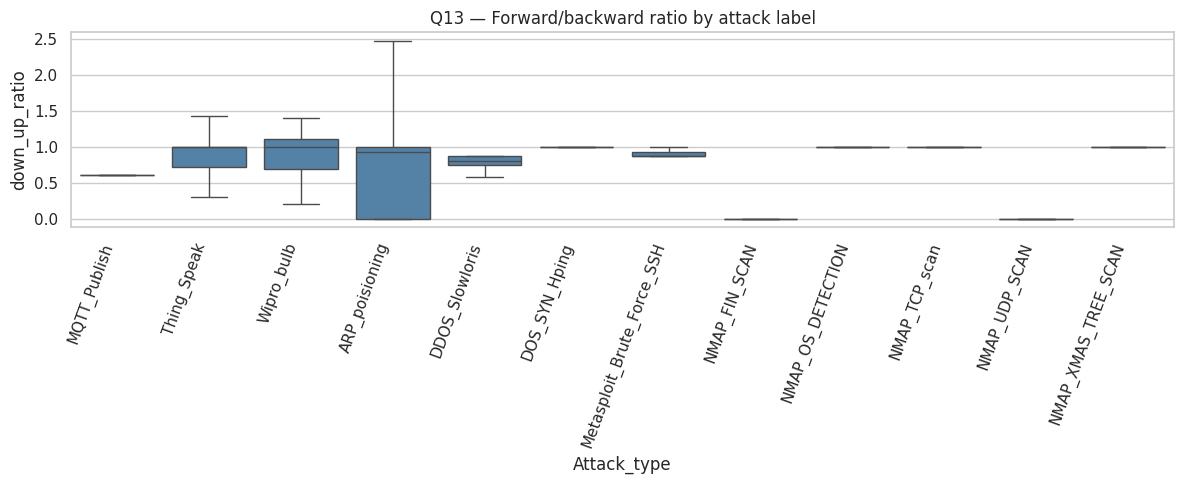

In [20]:
if "down_up_ratio" in df.columns:
    groups, names = [], []
    for name, g in df.groupby("Attack_type"):
        x = g["down_up_ratio"].dropna()
        if len(x) >= 30:
            groups.append(x.to_numpy())
            names.append(name)
    display(df.groupby("Attack_type")["down_up_ratio"].agg(["count", "median", "mean", "std"]).sort_values("median", ascending=False).round(4))
    if len(groups) >= 2:
        H, p = kruskal(*groups)
        print(f"Q13 Kruskal-Wallis H={H:.4f}; p-value={p:.6g}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=df, x="Attack_type", y="down_up_ratio", showfliers=False, color="steelblue")
    plt.title("Q13 — Forward/backward ratio by attack label")
    plt.xlabel("Attack_type")
    plt.ylabel("down_up_ratio")
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

### Q14. Do MQTT-service flows have a different flow-duration distribution from non-MQTT flows?

**Method:** Mann–Whitney U test comparing `service == 'mqtt'` with all other services. Report median difference and rank-biserial effect size.  
**\(H_0\):** MQTT and non-MQTT flow-duration distributions are equal.  
**\(H_1\):** They differ.  
**Why:** Flow duration is skewed and groups are independent at the row level as represented.  
**Caution:** This is an observational comparison; the service groups can differ in protocol, label, and collection scenario.

MQTT n=4,132, median=44.0937; non-MQTT n=118,985, median=0.0000
Q14 Mann–Whitney U=488313532.000; p-value=0; rank-biserial effect=0.9864
Decision: Reject H0


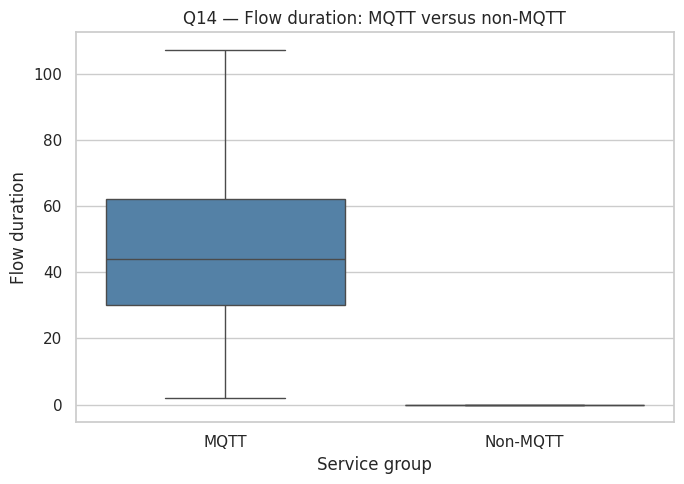

In [21]:
if {"service", "flow_duration"}.issubset(df.columns):
    mqtt = df.loc[df["service"].str.lower() == "mqtt", "flow_duration"].dropna()
    non_mqtt = df.loc[df["service"].str.lower() != "mqtt", "flow_duration"].dropna()
    print(f"MQTT n={len(mqtt):,}, median={mqtt.median():.4f}; non-MQTT n={len(non_mqtt):,}, median={non_mqtt.median():.4f}")
    if len(mqtt) and len(non_mqtt):
        U, p = mannwhitneyu(mqtt, non_mqtt, alternative="two-sided")
        rbc = 2 * U / (len(mqtt) * len(non_mqtt)) - 1
        print(f"Q14 Mann–Whitney U={U:.3f}; p-value={p:.6g}; rank-biserial effect={rbc:.4f}")
        print("Decision:", "Reject H0" if p < .05 else "Fail to reject H0")
    tmp = df[df["service"].str.lower().eq("mqtt") | df["service"].str.lower().ne("mqtt")]
    tmp = tmp.assign(service_group=np.where(tmp["service"].str.lower() == "mqtt", "MQTT", "Non-MQTT"))
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=tmp, x="service_group", y="flow_duration", showfliers=False, color="steelblue")
    plt.title("Q14 — Flow duration: MQTT versus non-MQTT")
    plt.xlabel("Service group")
    plt.ylabel("Flow duration")
    plt.tight_layout()
    plt.show()

### Q15. Can flow features distinguish the recorded attack labels?

**Supporting technique:** Multiclass classification. This is included because `Attack_type` is a categorical label, but the case study remains statistics-first: the previous 14 questions and their interpretations are the main analysis.

**Model:** Random Forest classifier with class weighting. A stratified sample is used to keep runtime manageable while retaining representation of minority labels. The row-index field and target label are excluded from predictors; `id.orig_p` and `id.resp_p` are excluded from the primary model to reduce reliance on port-specific collection shortcuts.

**Evaluation:** Macro-F1, balanced accuracy, per-class precision/recall/F1, confusion matrix, and majority-class baseline. Because classes are imbalanced, overall accuracy is not sufficient.

In [22]:
# Prepare modelling data without the target, index-like ID, or raw port fields.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

exclude_predictors = {"Attack_type", "id.orig_p", "id.resp_p"}
model_features = [c for c in df.columns if c not in exclude_predictors]
model_data = df[model_features + ["Attack_type"]].replace([np.inf, -np.inf], np.nan).copy()

# Stratified sample: cap at 50,000 rows to make notebook execution more practical.
MAX_MODEL_ROWS = 50000
if len(model_data) > MAX_MODEL_ROWS:
    model_data, _ = train_test_split(
        model_data, train_size=MAX_MODEL_ROWS, random_state=42,
        stratify=model_data["Attack_type"]
    )

X = model_data[model_features]
y = model_data["Attack_type"]

# Drop any feature that is entirely missing.
usable_features = [c for c in X.columns if not X[c].isna().all()]
X = X[usable_features]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print(f"Rows used for model: {len(X):,}")
print(f"Numeric predictors: {len(numeric_features)}; categorical predictors: {len(categorical_features)}")
print("Class counts in modelling data:")
display(y.value_counts().to_frame("records"))

Rows used for model: 50,000
Numeric predictors: 80; categorical predictors: 2
Class counts in modelling data:


,records
Attack_type,
DOS_SYN_Hping,38443
Thing_Speak,3293
ARP_poisioning,3147
MQTT_Publish,1684
NMAP_UDP_SCAN,1052
NMAP_XMAS_TREE_SCAN,816
NMAP_OS_DETECTION,812
NMAP_TCP_scan,407
DDOS_Slowloris,217


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

rf = RandomForestClassifier(
    n_estimators=120,
    max_depth=18,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", rf)
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

model_metrics = pd.DataFrame([
    {
        "model": "Random Forest",
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "macro_F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "weighted_F1": f1_score(y_test, pred, average="weighted", zero_division=0)
    },
    {
        "model": "Majority-class baseline",
        "accuracy": accuracy_score(y_test, baseline_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, baseline_pred),
        "macro_F1": f1_score(y_test, baseline_pred, average="macro", zero_division=0),
        "weighted_F1": f1_score(y_test, baseline_pred, average="weighted", zero_division=0)
    }
])
display(model_metrics.round(4))

,model,accuracy,balanced_accuracy,macro_F1,weighted_F1
0,Random Forest,0.9948,0.9380,0.9338,0.9948
1,Majority-class baseline,0.7689,0.0833,0.0724,0.6684


Per-class evaluation on the held-out test split:
                            precision    recall  f1-score   support

            ARP_poisioning       0.96      0.99      0.98       630
            DDOS_Slowloris       0.80      0.95      0.87        43
             DOS_SYN_Hping       1.00      1.00      1.00      7689
              MQTT_Publish       1.00      1.00      1.00       337
Metasploit_Brute_Force_SSH       1.00      0.67      0.80         3
             NMAP_FIN_SCAN       0.67      1.00      0.80         2
         NMAP_OS_DETECTION       1.00      1.00      1.00       162
             NMAP_TCP_scan       1.00      0.99      0.99        81
             NMAP_UDP_SCAN       0.96      0.93      0.94       210
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       163
               Thing_Speak       0.99      0.97      0.98       659
                Wipro_bulb       0.94      0.76      0.84        21

                  accuracy                           0.99     100

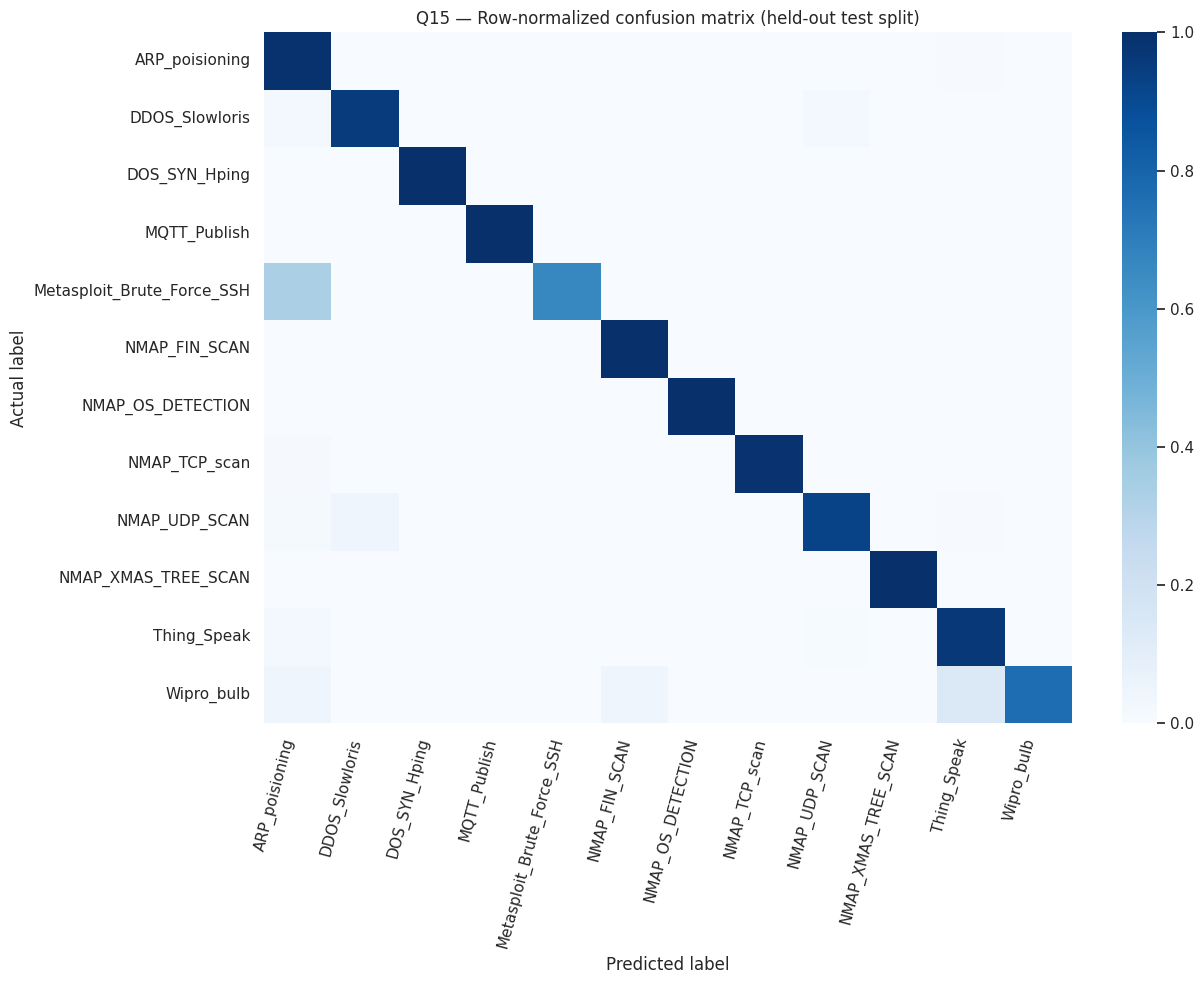

In [24]:
print("Per-class evaluation on the held-out test split:")
print(classification_report(y_test, pred, zero_division=0))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
plt.figure(figsize=(13, 10))
sns.heatmap(cm, xticklabels=labels, yticklabels=labels, cmap="Blues", vmin=0, vmax=1)
plt.title("Q15 — Row-normalized confusion matrix (held-out test split)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Model interpretation checklist

- Compare the Random Forest with the majority-class baseline, especially on macro-F1 and balanced accuracy.
- Use per-class recall to see whether rare labels are missed.
- Review the confusion matrix for specific confusions rather than reporting one score only.
- Class weighting helps but does not guarantee good performance for labels with very few examples.
- Because the test split is sampled from the same dataset, it does not prove the model will work on unseen devices, networks, collection sessions, or future traffic.
- A more stringent follow-up would use grouped or time-aware validation if a reliable session/device/time identifier is available. The supplied file does not expose an obvious timestamp column in the expected schema.
- Do not claim that the model or any feature causes an attack.

## 7. Cross-question synthesis

This section gathers outputs that can support the written report. Complete the narrative after running the notebook, using actual values rather than assumptions.

In [25]:
# Compact summaries for the report
print("DATASET")
print(f"Rows={len(df):,}; columns={df.shape[1]}; attack labels={df['Attack_type'].nunique()}")
print(f"Exact duplicates removed={raw_duplicate_count:,}; repeated feature signatures (label ignored)={feature_signature_duplicates:,}")
print("\nTOP LABELS (%)")
display((df["Attack_type"].value_counts(normalize=True).head(8) * 100).round(2).rename("percent").to_frame())
if "proto" in df.columns:
    print("\nPROTOCOL COUNTS")
    display(df["proto"].value_counts().to_frame("records"))
if "service" in df.columns:
    print("\nTOP SERVICES")
    display(df["service"].value_counts().head(10).to_frame("records"))

DATASET
Rows=123,117; columns=85; attack labels=12
Exact duplicates removed=0; repeated feature signatures (label ignored)=5,202

TOP LABELS (%)


,percent
Attack_type,
DOS_SYN_Hping,76.89
Thing_Speak,6.59
ARP_poisioning,6.29
MQTT_Publish,3.37
NMAP_UDP_SCAN,2.1
NMAP_XMAS_TREE_SCAN,1.63
NMAP_OS_DETECTION,1.62
NMAP_TCP_scan,0.81



PROTOCOL COUNTS


,records
proto,
tcp,110427
udp,12633
icmp,57



TOP SERVICES


,records
service,
-,102861
dns,9753
mqtt,4132
http,3464
ssl,2663
ntp,121
dhcp,50
irc,43
ssh,28


## 8. Export tables for Power BI / Tableau

These CSV files can be imported into Power BI or Tableau. They support views such as attack-label distribution, protocol/service composition, feature summaries by label, and correlation exploration.

In [26]:
OUTPUT_DIR = Path("iot_pulse_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.to_csv(OUTPUT_DIR / "iot_pulse_clean_flows.csv", index=False)

label_export = df.groupby("Attack_type").size().rename("records").reset_index()
label_export["percent"] = label_export["records"] / label_export["records"].sum() * 100
label_export.to_csv(OUTPUT_DIR / "attack_label_summary.csv", index=False)

if "proto" in df.columns:
    pd.crosstab(df["proto"], df["Attack_type"]).to_csv(OUTPUT_DIR / "protocol_by_attack.csv")

if "service" in df.columns:
    pd.crosstab(df["service"], df["Attack_type"]).to_csv(OUTPUT_DIR / "service_by_attack.csv")

feature_candidates = [c for c in [
    "flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec",
    "payload_bytes_per_second", "flow_SYN_flag_count", "flow_ACK_flag_count",
    "down_up_ratio", "flow_iat.avg", "active.avg", "idle.avg"
] if c in df.columns]
if feature_candidates:
    feature_by_label = df.groupby("Attack_type")[feature_candidates].agg(["count", "median", "mean", "std"])
    feature_by_label.to_csv(OUTPUT_DIR / "feature_summary_by_attack.csv")

if len(feature_candidates) >= 2:
    df[feature_candidates].corr(method="spearman").to_csv(OUTPUT_DIR / "selected_feature_spearman_correlation.csv")

print("Exported files:")
for file in sorted(OUTPUT_DIR.glob("*.csv")):
    print(f"- {file.name}: {file.stat().st_size:,} bytes")

Exported files:
- attack_label_summary.csv: 498 bytes
- feature_summary_by_attack.csv: 7,258 bytes
- iot_pulse_clean_flows.csv: 52,625,880 bytes
- protocol_by_attack.csv: 319 bytes
- selected_feature_spearman_correlation.csv: 2,533 bytes
- service_by_attack.csv: 536 bytes


## 9. Evidence-based conclusions (generated from the actual run)

The next cells assemble a compact evidence table and generate a data-dependent conclusion draft from the results computed above. Review the wording before submission: statistical significance is not causation, and p-values can be optimistic if flows are dependent or collected in clusters. Do not copy a conclusion if a test was skipped because the relevant field was absent.

### 9.1 Consolidated inferential results and multiple-testing adjustment

For the family of exploratory tests in this notebook, the following cell recomputes the key tests consistently and applies the Benjamini–Hochberg false-discovery-rate adjustment across the available p-values. The adjusted p-values complement—not replace—the original test results. This is an exploratory family, so state clearly which tests you treat as confirmatory in the report.

## 10. Limitations and future work

### Limitations
- **Class imbalance:** The dataset is dominated by a small number of labels; minority-label estimates and model scores can be unstable.
- **Collection-specific patterns:** Protocol, service, and port patterns may reflect how the data was generated, not universal attack signatures.
- **Observational records:** Statistical association does not establish causation.
- **Dependence:** Similar flows may not be independent; standard inferential tests can understate uncertainty when records are clustered.
- **Derived features:** Rates and totals may share mathematical components, making some correlations expected.
- **No obvious timestamp in the supplied schema:** Trend analysis and chronological validation are not supported without an appropriate time field.
- **Model generalization:** A random held-out split is not a substitute for evaluation on a new network or collection session.

### Future enhancements
- Validate findings on a second independent IoT traffic dataset.
- Use session/device/group-aware validation if metadata becomes available.
- Pre-plan pairwise post-hoc tests with multiple-comparison correction.
- Report confidence intervals for key effect sizes and check robustness to class balancing.
- Confirm feature definitions and units against the dataset documentation.

## 11. References

1. **RT-IOT2022 dataset** — use the source link or citation supplied with the downloaded dataset. Record the exact version and access date in the final report.
2. **Course material:** 23CSE351 Foundations of Data Science lecture notes on preprocessing, measures of central tendency and dispersion, sampling, hypothesis testing, statistical testing, and causation/experiments.
3. SciPy statistical functions: https://docs.scipy.org/doc/scipy/reference/stats.html
4. scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
5. scikit-learn Random Forest: https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees

## Final submission checklist

- [ ] Dataset has more than 500 records and the exact source/version is documented.
- [ ] All 15 questions are run and interpreted with actual outputs.
- [ ] Hypotheses, test statistics, p-values, and effect sizes/intervals are included where applicable.
- [ ] Statistical significance is distinguished from practical importance.
- [ ] Observational comparisons are not described as causal experiments.
- [ ] Classification is supporting analysis, not the entire project.
- [ ] Macro-F1, balanced accuracy, per-class metrics, and baseline comparison are reported.
- [ ] Visualizations have clear titles and axis labels.
- [ ] Power BI/Tableau export files are generated.
- [ ] Report and 10–12-slide presentation include objectives, dataset, preprocessing, EDA, statistical analysis, model, findings, limitations, and references.

In [27]:
# Recompute key inferential tests into one consistent table and apply Benjamini-Hochberg correction.
from statsmodels.stats.multitest import multipletests

inferential_rows = []
def add_test(question, method, statistic, p_value, n, effect_name=None, effect_value=np.nan, note=""):
    inferential_rows.append({"question": question, "test": method, "statistic": statistic,
                             "p_value": float(p_value), "n": int(n),
                             "effect_size": effect_name, "effect_value": effect_value, "note": note})

# Q2: protocol x attack label
if "proto" in df.columns:
    ct = pd.crosstab(df["proto"], df["Attack_type"])
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, pval, dof, exp = chi2_contingency(ct)
        v = np.sqrt(chi2 / (ct.to_numpy().sum() * min(ct.shape[0]-1, ct.shape[1]-1)))
        add_test("Q2 Protocol × attack label", "Chi-square independence", chi2, pval, ct.to_numpy().sum(), "Cramer's V", v,
                 f"Expected cells <5: {(exp < 5).sum()}/{exp.size}")

# Q3: service group x attack label
if "service" in df.columns:
    counts = df["service"].value_counts()
    common = counts[counts >= 100].index
    sgroup = df["service"].where(df["service"].isin(common), "Other service")
    ct = pd.crosstab(sgroup, df["Attack_type"])
    if ct.shape[0] > 1 and ct.shape[1] > 1:
        chi2, pval, dof, exp = chi2_contingency(ct)
        v = np.sqrt(chi2 / (ct.to_numpy().sum() * min(ct.shape[0]-1, ct.shape[1]-1)))
        add_test("Q3 Service group × attack label", "Chi-square independence", chi2, pval, ct.to_numpy().sum(), "Cramer's V", v,
                 f"Expected cells <5: {(exp < 5).sum()}/{exp.size}")

# Kruskal-Wallis helper for multi-class numeric comparisons
for q, feature in [("Q4 Flow duration by attack label", "flow_duration"),
                   ("Q5 Total packets by attack label", "total_pkts"),
                   ("Q9 SYN flags by attack label", "flow_SYN_flag_count"),
                   ("Q13 Directional ratio by attack label", "down_up_ratio")]:
    if feature in df.columns:
        arr = [g[feature].dropna().to_numpy() for _, g in df.groupby("Attack_type") if g[feature].notna().sum() >= 30]
        n = sum(len(a) for a in arr)
        if len(arr) >= 2:
            statv, pval = kruskal(*arr)
            add_test(q, "Kruskal–Wallis", statv, pval, n, note=f"Groups included: {len(arr)}")

# Spearman associations
for q, a, b in [("Q6 Forward vs backward packets", "fwd_pkts_tot", "bwd_pkts_tot"),
                ("Q11 Duration vs packet rate", "flow_duration", "flow_pkts_per_sec")]:
    if {a,b}.issubset(df.columns):
        pair = df[[a,b]].replace([np.inf,-np.inf],np.nan).dropna()
        if len(pair) >= 3:
            rho, pval = spearmanr(pair[a], pair[b])
            add_test(q, "Spearman correlation", rho, pval, len(pair), "Spearman rho", rho)

# Two-group protocol comparisons
for q, feature in [("Q7 TCP vs UDP packet rate", "flow_pkts_per_sec"),
                   ("Q8 TCP vs UDP payload rate", "payload_bytes_per_second")]:
    if {"proto",feature}.issubset(df.columns):
        x = df.loc[df["proto"].str.lower()=="tcp", feature].dropna()
        y = df.loc[df["proto"].str.lower()=="udp", feature].dropna()
        if len(x) and len(y):
            u, pval = mannwhitneyu(x,y,alternative="two-sided")
            rbc = 2*u/(len(x)*len(y))-1
            add_test(q, "Mann–Whitney U", u, pval, len(x)+len(y), "Rank-biserial correlation", rbc,
                     f"TCP n={len(x)}; UDP n={len(y)}")

# Q14 MQTT vs non-MQTT duration
if {"service","flow_duration"}.issubset(df.columns):
    x = df.loc[df["service"].str.lower()=="mqtt", "flow_duration"].dropna()
    y = df.loc[df["service"].str.lower()!="mqtt", "flow_duration"].dropna()
    if len(x) and len(y):
        u,pval=mannwhitneyu(x,y,alternative="two-sided")
        rbc=2*u/(len(x)*len(y))-1
        add_test("Q14 MQTT vs non-MQTT duration", "Mann–Whitney U", u, pval, len(x)+len(y), "Rank-biserial correlation", rbc,
                 f"MQTT n={len(x)}; non-MQTT n={len(y)}")

results_df = pd.DataFrame(inferential_rows)
if not results_df.empty:
    results_df["p_value_adjusted_BH"] = multipletests(results_df["p_value"].clip(lower=np.finfo(float).tiny), method="fdr_bh")[1]
    results_df["significant_raw_0.05"] = results_df["p_value"] < 0.05
    results_df["significant_BH_0.05"] = results_df["p_value_adjusted_BH"] < 0.05
    display(results_df.sort_values("p_value").round(6))
    results_df.to_csv(OUTPUT_DIR / "inferential_test_summary_with_BH.csv", index=False)
else:
    print("No inferential tests could be recomputed; check the dataset's column names.")


,question,test,statistic,p_value,n,effect_size,effect_value,note,p_value_adjusted_BH,significant_raw_0.05,significant_BH_0.05
0,Q2 Protocol × attack label,Chi-square independence,8.380312e+04,0.0,123117,Cramer's V,0.583386,Expected cells <5: 13/36,0.0,True,True
1,Q3 Service group × attack label,Chi-square independence,3.017291e+05,0.0,123117,Cramer's V,0.639108,Expected cells <5: 26/84,0.0,True,True
2,Q4 Flow duration by attack label,Kruskal–Wallis,4.474948e+04,0.0,123089,None,NaN,Groups included: 11,0.0,True,True
3,Q5 Total packets by attack label,Kruskal–Wallis,5.930294e+04,0.0,123089,None,NaN,Groups included: 11,0.0,True,True
4,Q9 SYN flags by attack label,Kruskal–Wallis,5.788320e+04,0.0,123089,None,NaN,Groups included: 11,0.0,True,True
5,Q13 Directional ratio by attack label,Kruskal–Wallis,3.518837e+04,0.0,123089,None,NaN,Groups included: 11,0.0,True,True
6,Q6 Forward vs backward packets,Spearman correlation,7.462690e-01,0.0,123117,Spearman rho,0.746269,,0.0,True,True
7,Q11 Duration vs packet rate,Spearman correlation,-2.959300e-01,0.0,123117,Spearman rho,-0.295930,,0.0,True,True
8,Q7 TCP vs UDP packet rate,Mann–Whitney U,1.207681e+09,0.0,123060,Rank-biserial correlation,0.731413,TCP n=110427; UDP n=12633,0.0,True,True
9,Q8 TCP vs UDP payload rate,Mann–Whitney U,1.159424e+09,0.0,123060,Rank-biserial correlation,0.662228,TCP n=110427; UDP n=12633,0.0,True,True


### 9.2 Practical interpretation of the model

A classification model is included to satisfy the requirement to select and evaluate one technique. It is not the central purpose of this project. Use macro-F1 and balanced accuracy to account for imbalance, compare against the majority baseline, and inspect class-level recall. Avoid presenting feature importance as causal evidence.


,model,accuracy,balanced_accuracy,macro_F1,weighted_F1
0,Random Forest,0.9948,0.9380,0.9338,0.9948
1,Majority-class baseline,0.7689,0.0833,0.0724,0.6684


,importance
num__fwd_header_size_min,0.042828
num__fwd_last_window_size,0.042505
num__fwd_PSH_flag_count,0.036397
num__fwd_URG_flag_count,0.036347
num__fwd_pkts_payload.avg,0.033926
num__flow_iat.min,0.033252
num__fwd_pkts_payload.max,0.030829
num__flow_FIN_flag_count,0.029014
num__flow_pkts_payload.max,0.026515
num__bwd_pkts_per_sec,0.025743


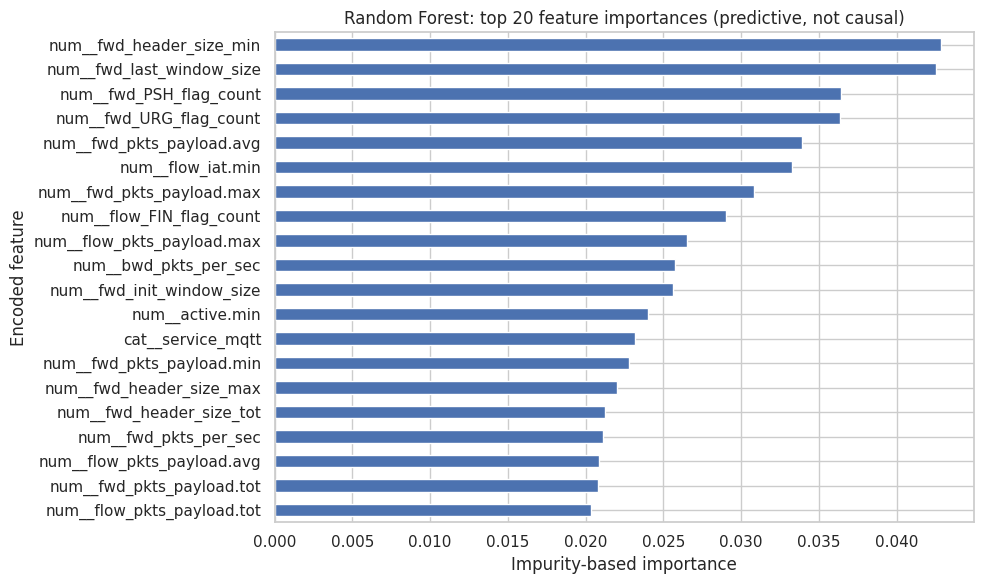

In [28]:
# Model evidence summary and, where supported, feature importance.
if "model_metrics" in globals():
    display(model_metrics.round(4))
    rf_estimator = model.named_steps["classifier"]
    try:
        feature_names = model.named_steps["preprocess"].get_feature_names_out()
        importances = pd.Series(rf_estimator.feature_importances_, index=feature_names).sort_values(ascending=False).head(20)
        display(importances.rename("importance").to_frame())
        plt.figure(figsize=(10,6))
        importances.sort_values().plot(kind="barh")
        plt.title("Random Forest: top 20 feature importances (predictive, not causal)")
        plt.xlabel("Impurity-based importance")
        plt.ylabel("Encoded feature")
        plt.tight_layout()
        plt.show()
        importances.rename("importance").to_csv(OUTPUT_DIR / "random_forest_top_feature_importance.csv")
    except Exception as e:
        print("Feature-importance extraction was unavailable:", e)
else:
    print("Model metrics are not available. Run the model cells above first.")


### 9.3 Generated conclusion draft

The following summary is generated from the computed data. It deliberately avoids claiming causation or generalizing beyond the dataset. Edit it after reviewing all plots and the data-collection documentation.


In [29]:
# Build a concise conclusion from actual data and available test results.
majority_label = df["Attack_type"].value_counts().index[0]
majority_share = df["Attack_type"].value_counts(normalize=True).iloc[0] * 100
least_label = df["Attack_type"].value_counts().index[-1]
least_share = df["Attack_type"].value_counts(normalize=True).iloc[-1] * 100
print("FINAL CONCLUSION DRAFT — verify and adapt for the report")
print(f"The cleaned analytical dataset contains {len(df):,} records and {df['Attack_type'].nunique()} recorded attack labels.")
print(f"The most represented label is {majority_label} ({majority_share:.2f}%); the least represented label is {least_label} ({least_share:.3f}%). This imbalance means that accuracy alone is insufficient for evaluating a classifier.")
if not results_df.empty:
    sig_raw = int(results_df["significant_raw_0.05"].sum())
    sig_bh = int(results_df["significant_BH_0.05"].sum())
    print(f"Across {len(results_df)} recomputed exploratory inferential tests, {sig_raw} have raw p-values below 0.05 and {sig_bh} remain below 0.05 after Benjamini–Hochberg adjustment.")
    print("A small p-value indicates evidence against the relevant null model; it does not by itself indicate a large or operationally important effect. Review effect sizes and expected-cell diagnostics before drawing conclusions.")
if "model_metrics" in globals():
    rfrow = model_metrics.loc[model_metrics["model"]=="Random Forest"].iloc[0]
    baserow = model_metrics.loc[model_metrics["model"]=="Majority-class baseline"].iloc[0]
    print(f"On the held-out split, Random Forest macro-F1={rfrow['macro_F1']:.4f} and balanced accuracy={rfrow['balanced_accuracy']:.4f}; the majority baseline macro-F1={baserow['macro_F1']:.4f} and balanced accuracy={baserow['balanced_accuracy']:.4f}.")
    print("Interpret model performance as within-dataset evidence only; independent-network validation is required before operational deployment.")
print("The high-SYN comparison is observational, not a randomized A/B experiment. No causal claim can be made from these records.")
print("Limitations include class imbalance, potential dependence among flow records, collection-specific patterns, derived-feature relationships, and uncertain generalization to unseen networks.")


FINAL CONCLUSION DRAFT — verify and adapt for the report
The cleaned analytical dataset contains 123,117 records and 12 recorded attack labels.
The most represented label is DOS_SYN_Hping (76.89%); the least represented label is NMAP_FIN_SCAN (0.023%). This imbalance means that accuracy alone is insufficient for evaluating a classifier.
Across 11 recomputed exploratory inferential tests, 11 have raw p-values below 0.05 and 11 remain below 0.05 after Benjamini–Hochberg adjustment.
A small p-value indicates evidence against the relevant null model; it does not by itself indicate a large or operationally important effect. Review effect sizes and expected-cell diagnostics before drawing conclusions.
On the held-out split, Random Forest macro-F1=0.9338 and balanced accuracy=0.9380; the majority baseline macro-F1=0.0724 and balanced accuracy=0.0833.
Interpret model performance as within-dataset evidence only; independent-network validation is required before operational deployment.
The high-

## 10. A/B-testing requirement: explicit academic note

The available RT-IOT2022 records are observational labelled network flows; they do not show randomized assignment to a treatment and control condition. Therefore, the notebook's TCP/UDP and high-SYN group comparisons are **two-group statistical comparisons**, not randomized A/B experiments.

If the instructor uses “A/B testing” to mean any comparison between two groups, clearly label the analysis observational. If the instructor requires a genuine experiment, obtain approval for a defensible experiment with an explicit intervention, randomized assignment, pre-defined outcome, and sample-size plan. Do not fabricate randomized data or call existing labels treatment assignments.


## 11. Report and presentation handoff

The notebook satisfies the notebook component; it does not automatically create the separate case-study report or 10–12-slide presentation. Use the actual outputs to prepare them in this order:

1. Title, student details, and project name.
2. Problem statement and objectives.
3. Dataset source, version, dimensions, and attribute descriptions.
4. Preprocessing choices and data-quality findings.
5. EDA: class balance and selected feature distributions.
6. Statistical hypotheses, tests, p-values, adjusted p-values, effect sizes, and observational-comparison caveat.
7. Random Forest methodology, parameters, assumptions, baseline, and metrics.
8. Python/Power BI/Tableau visualizations.
9. Key findings supported by calculated evidence.
10. Conclusion and limitations.
11. Future enhancements.
12. References and dataset attribution.

Keep the presentation to 8–10 minutes, use titled and labelled charts, and explain the meaning of results rather than showing numbers without interpretation.
